# TE summary stats

This notebook gives summary statistics on what the TEs identify are like. What strains, divergences, etc. Specifically, I perform this analysis on TEs identified through the new system of directly feeding insertions to RepeatMasker, ignoring any issues with reference flanking sequence.

In [3]:
import pandas as pd

/Users/aarontran/opt/anaconda3/lib/python3.8/site-packages/pandas/core/computation/expressions.py:20: UserWarning: Pandas requires version '2.7.3' or newer of 'numexpr' (version '2.7.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [7]:
my_headers = ["SW", "perc div.", "perc del.", "perc ins.", "query sequence", "begin", "end", "remaining", "strand", "matching", "class", "consensusOverhang", "repeatStart", "repeatEnd", "ID", "isWeakerOverlap"]
F1=pd.read_table("F1_rpmasker.fa.out",
              sep="\\s+",
              skiprows=[0,1], 
              usecols=range(16),
              header=None,
              names=my_headers)

In [8]:
F2=pd.read_table("F2_rpmasker.fa.out",
              sep="\\s+",
              skiprows=[0,1], 
              usecols=range(16),
              header=None,
              names=my_headers)

M1=pd.read_table("M1_rpmasker.fa.out",
              sep="\\s+",
              skiprows=[0,1], 
              usecols=range(16),
              header=None,
              names=my_headers)

In [9]:
F1

,SW,perc div.,perc del.,perc ins.,query sequence,begin,end,remaining,strand,matching,class,consensusOverhang,repeatStart,repeatEnd,ID,isWeakerOverlap
0,2145,12.3,0.0,0.7,chr1-12221713-ALT,1,310,(2021),C,AluSx,SINE/Alu,(4),308,1,1,NaN
1,803,30.4,0.0,2.0,chr1-12221713-ALT,318,569,(1762),C,MLT1N2-int,LTR/ERVL,(4356),1324,1078,2,NaN
2,1918,16.5,1.3,0.3,chr1-12221713-ALT,576,873,(1458),+,AluJb,SINE/Alu,1,301,(11),3,NaN
3,1178,24.2,0.7,5.5,chr1-12221713-ALT,936,1004,(1327),C,MLT1F2,LTR/ERVL-MaLR,(0),560,498,4,NaN
4,2597,4.2,0.3,2.9,chr1-12221713-ALT,1005,1323,(1008),+,AluY,SINE/Alu,1,311,(0),5,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13077,517,23.0,4.9,1.8,chrX-151099745-NULL,1,164,(1838),+,L2a,LINE/L2,3228,3396,(30),10760,NaN
13078,385,23.8,3.9,5.5,chrX-151099745-NULL,463,591,(1411),+,MIRb,SINE/MIR,87,213,(55),10761,NaN
13079,2396,15.8,2.1,2.1,chrX-151099745-NULL,625,1058,(944),+,Tigger2a,DNA/TcMar-Tigger,1,434,(0),10762,NaN
13080,503,30.9,1.8,2.3,chrX-151343162-ALT,1810,2210,(67),C,MamGyp-int,LTR/Gypsy,(4144),958,560,10763,NaN


In [10]:
F1['remaining'].dtype

dtype('O')

In [11]:
def create_filter_mask(df):
    """
    Create boolean mask for filtering variant dataframes.
    
    Filters for:
    - "ALT" in query sequence
    - 80% of aligned region is 1000bp+ from either end
    """
    # Clean the 'remaining' column
    remaining_clean = df['remaining'].str.strip('()').astype(int)
    
    # Condition 1: "ALT" in sequence name
    mask_alt = df['query sequence'].str.contains('ALT')
    
    # Condition 2: 80% of aligned region is 1000bp+ away from either end
    total_length = df['end'] + remaining_clean
    safe_start = 1000
    safe_end = total_length - 1000
    
    # Find intersection of aligned region [begin, end] with safe zone
    intersection_start = df['begin'].clip(lower=safe_start)
    intersection_end = df['end'].clip(upper=safe_end)
    intersection_length = (intersection_end - intersection_start).clip(lower=0)
    
    # Length of aligned region
    aligned_length = df['end'] - df['begin']
    
    # Check if 80% or more is in safe zone
    mask_distance = intersection_length >= 0.8 * aligned_length
    
    # Combine both conditions
    return mask_alt & mask_distance

# Apply to any dataframe
filtered_F1 = F1[create_filter_mask(F1)]
filtered_F2 = F2[create_filter_mask(F2)]
filtered_M1 = M1[create_filter_mask(M1)]

# drop all rows without NaN (that is, keep only the best or of the non-overlaps)
F1_weak = filtered_F1.dropna(subset=['isWeakerOverlap'])
F1_strong = filtered_F1.drop(F1_weak.index)

F2_weak = filtered_F2.dropna(subset=['isWeakerOverlap'])
F2_strong = filtered_F2.drop(F2_weak.index)

M1_weak = filtered_M1.dropna(subset=['isWeakerOverlap'])
M1_strong = filtered_M1.drop(M1_weak.index)

In [12]:
F1_strong

,SW,perc div.,perc del.,perc ins.,query sequence,begin,end,remaining,strand,matching,class,consensusOverhang,repeatStart,repeatEnd,ID,isWeakerOverlap
4,2597,4.2,0.3,2.9,chr1-12221713-ALT,1005,1323,(1008),+,AluY,SINE/Alu,1,311,(0),5,NaN
17,2073,1.7,0.0,0.4,chr1-12360369-ALT,1012,1275,(1001),C,L1HS,LINE/L1,(0),6155,5915,15,NaN
46,280,27.0,0.0,1.1,chr1-28078-ALT,1065,1154,(1289),C,L1MD3,LINE/L1,(1368),6627,6539,36,NaN
48,18,3.9,7.4,0.0,chr1-28078-ALT,1235,1261,(1182),+,(TA)n,Simple_repeat,1,29,(0),37,NaN
49,282,27.2,3.9,3.1,chr1-28078-ALT,1288,1416,(1027),C,L1MD3,LINE/L1,(1327),6668,6539,38,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13051,18,25.6,5.2,0.0,chrX-134103428-ALT,69202,69259,(1862),+,(AT)n,Simple_repeat,1,61,(0),10736,NaN
13052,50,0.0,0.0,0.0,chrX-134103428-ALT,69308,69350,(1771),+,(AC)n,Simple_repeat,1,43,(0),10737,NaN
13053,1159,27.7,3.6,0.0,chrX-134103428-ALT,69411,69717,(1404),+,ERVL67B-int,LTR/ERVL,4963,5280,(382),10731,NaN
13060,5510,16.9,3.1,1.1,chrX-139699848-ALT,1610,3256,(1245),+,L1MA7,LINE/L1,4597,6285,(6),10744,NaN


In [53]:
F1_strong[F1_strong.duplicated(subset=['ID'], keep=False)]

,SW,perc div.,perc del.,perc ins.,query sequence,begin,end,remaining,strand,matching,class,consensusOverhang,repeatStart,repeatEnd,ID,isWeakerOverlap
126,1254,20.4,11.2,1.0,chr1-12757013-ALT,1108,1228,(60214),+,AluJb,SINE/Alu,5,155,(147),101,NaN
128,1254,20.4,11.2,1.0,chr1-12757013-ALT,1524,1668,(59774),+,AluJb,SINE/Alu,156,299,(3),101,NaN
148,17530,7.0,0.1,0.0,chr1-12757013-ALT,12690,15525,(45917),+,L1PA7,LINE/L1,3,2840,(3306),122,NaN
151,19408,6.9,0.5,0.3,chr1-12757013-ALT,15846,19164,(42278),+,L1PA7,LINE/L1,2829,6154,(0),122,NaN
154,3065,18.8,3.6,2.4,chr1-12757013-ALT,19678,19993,(41449),+,MER41G,LTR/ERV1,264,575,(310),126,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13029,254,11.4,0.0,0.0,chrX-134103428-ALT,60735,60769,(10352),+,AluJb,SINE/Alu,88,122,(180),10718,NaN
13030,936,16.0,6.6,0.5,chrX-134103428-ALT,60804,60985,(10136),+,AluJb,SINE/Alu,120,312,(0),10718,NaN
13043,948,34.9,6.2,2.2,chrX-134103428-ALT,64920,65563,(5558),+,ERVL67B-int,LTR/ERVL,2371,3039,(2641),10731,NaN
13046,2042,30.3,2.1,4.0,chrX-134103428-ALT,66028,66842,(4279),+,ERVL67B-int,LTR/ERVL,4061,4860,(802),10731,NaN


In [75]:
M1_strong['ID'].nunique()

2189

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [61]:
def plot_element_counts(dataframes_dict, title="Element Counts"):
    """
    Bar graph comparing number of elements across dataframes.
    
    Args:
        dataframes_dict: dict like {'F1': F1_df, 'F2': F2_df, ...}
        title: plot title
    """
    counts = {name: df['ID'].nunique() for name, df in dataframes_dict.items()}
    
    plt.figure(figsize=(8, 6))
    bars=plt.bar(counts.keys(), counts.values())
    plt.xlabel('Sample')
    plt.ylabel('Number of Elements')
    plt.title(title)
    plt.xticks(rotation=45)
    plt.tight_layout()
    
    plt.savefig(f"{title.replace(' ', '_')}.png", dpi=300, bbox_inches='tight')
    
    plt.show()

In [57]:
sns.set_style("whitegrid")  # or "darkgrid", "white", "dark", "ticks"
plt.rcParams['figure.figsize'] = (10, 6)  # Default figure size

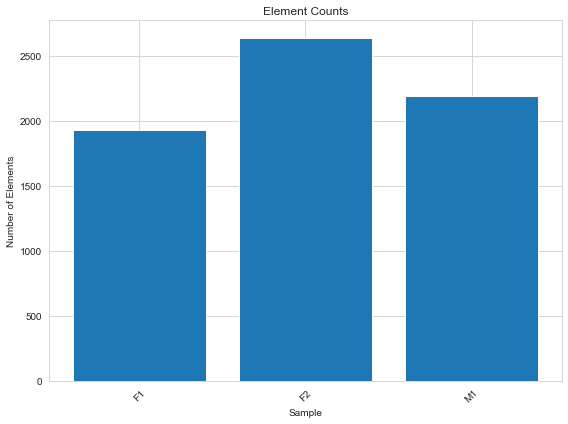

In [73]:
plot_element_counts({'F1':F1_strong, 'F2':F2_strong, 'M1':M1_strong})

In [15]:
# ============================================================================
# GLOBAL COLOR MAPPING - RUN THIS CELL ONCE
# ============================================================================

def create_global_class_colors(dataframes_list, threshold=1.0):
    """
    Create a consistent color mapping for all classes across all dataframes.
    
    Args:
        dataframes_list: list of dataframes to analyze
        threshold: percentage threshold for grouping classes
        
    Returns:
        Dictionary mapping class names to colors
    """
    all_classes = set()
    
    for df in dataframes_list:
        # Deduplicate by ID
        df_unique = df.drop_duplicates(subset='ID')
        
        # Get classes above threshold
        class_counts = df_unique['class'].value_counts()
        total = len(df_unique)
        percentages = (class_counts / total) * 100
        major_classes = percentages[percentages >= threshold].index
        all_classes.update(major_classes)
    
    # Always include "Other" for classes below threshold
    all_classes.add('Other')
    
    # Sort alphabetically for consistency
    sorted_classes = sorted(all_classes)
    
    # Assign colors from a large palette
    # Using tab20 for up to 20 classes, extend if needed
    n_classes = len(sorted_classes)
    if n_classes <= 10:
        palette = sns.color_palette('tab10', n_classes)
    elif n_classes <= 20:
        palette = sns.color_palette('tab20', n_classes)
    else:
        palette = sns.color_palette('husl', n_classes)
    
    color_map = dict(zip(sorted_classes, palette))
    
    print(f"Created global color map for {len(sorted_classes)} classes:")
    for cls in sorted_classes:
        print(f"  {cls}")
    
    return color_map


# Create the global color map - UPDATE THIS LIST WITH YOUR DATAFRAMES
GLOBAL_CLASS_COLORS = create_global_class_colors([F1_strong, F2_strong, M1_strong], threshold=1.0)

Created global color map for 14 classes:
  DNA/TcMar-Tigger
  DNA/hAT-Charlie
  LINE/L1
  LINE/L2
  LTR/ERV1
  LTR/ERVK
  LTR/ERVL
  LTR/ERVL-MaLR
  Low_complexity
  Other
  Retroposon/SVA
  SINE/Alu
  SINE/MIR
  Simple_repeat


In [142]:
def plot_class_distribution(df, title="Class Distribution"):
    """
    Pie chart showing proportion of different classes.
    Uses classes from GLOBAL_CLASS_COLORS.
    
    Args:
        df: dataframe with 'class' and 'ID' columns
        title: plot title
    """
    df_unique = df.drop_duplicates(subset='ID').copy()
    
    # Map all classes to either themselves (if in global map) or "Other"
    global_classes = set(GLOBAL_CLASS_COLORS.keys()) - {'Other'}
    df_unique['class_grouped'] = df_unique['class'].apply(
        lambda x: x if x in global_classes else 'Other'
    )
    
    class_counts = df_unique['class_grouped'].value_counts()
    
    # Sort alphabetically to match global color order
    sorted_classes = sorted(class_counts.index)
    plot_data = class_counts.reindex(sorted_classes)
    
    # Use global colors
    colors = [GLOBAL_CLASS_COLORS[cls] for cls in sorted_classes]
    
    plt.figure(figsize=(8, 8))
    plt.pie(plot_data.values, labels=plot_data.index, autopct='%1.1f%%',
            colors=colors, startangle=90)
    plt.title(title)
    plt.tight_layout()
    
    plt.savefig(f"/Users/aarontran/Desktop/wanglab/{title.replace(' ', '_')}.png", dpi=300, bbox_inches='tight', facecolor='white', transparent=False)
    plt.show()

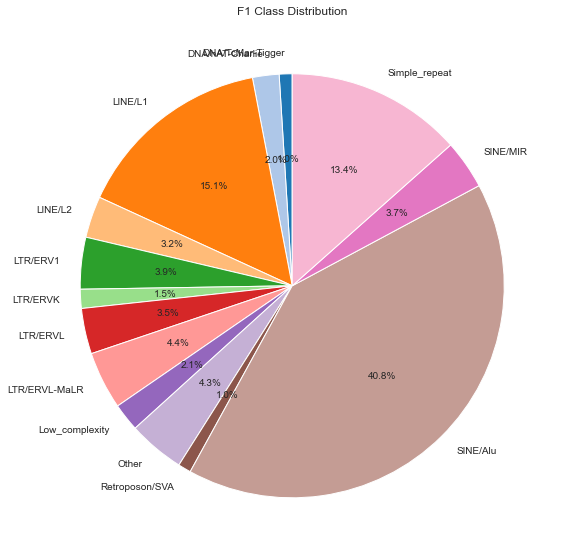

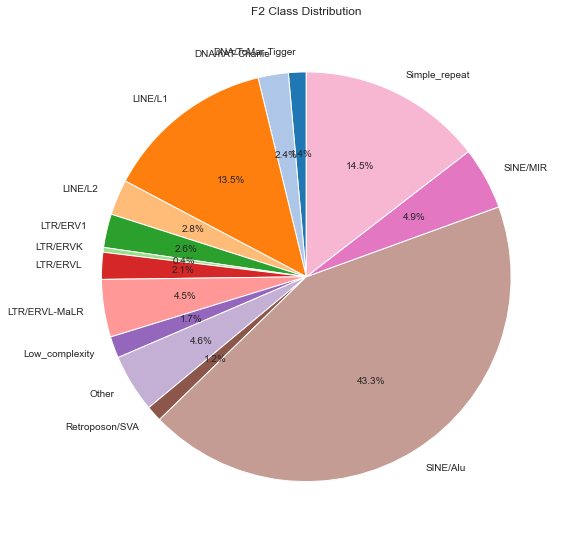

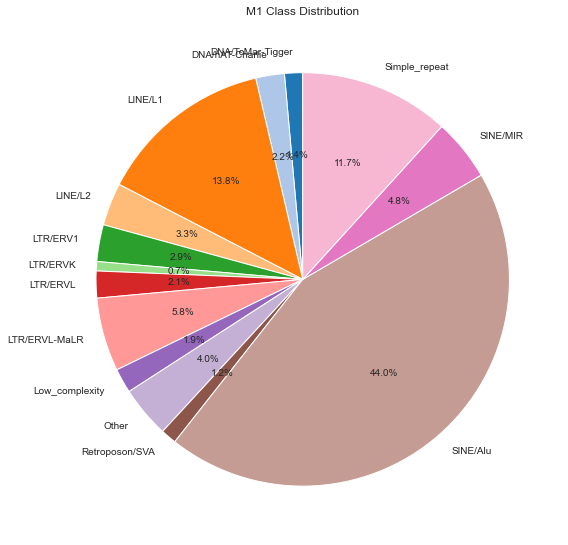

In [143]:
plot_class_distribution(F1_strong, title="F1 Class Distribution")
plot_class_distribution(F2_strong, title="F2 Class Distribution")
plot_class_distribution(M1_strong, title="M1 Class Distribution")

In [144]:
def plot_size_distribution(df, title="Size Distribution by Class"):
    """
    Dot plot of alignment sizes colored by class.
    For rows sharing the same ID, sizes are summed together.
    Uses classes from GLOBAL_CLASS_COLORS.
    
    Args:
        df: dataframe with 'begin', 'end', 'class', and 'ID' columns
        title: plot title
    """
    df_copy = df.copy()
    df_copy['size'] = df_copy['end'] - df_copy['begin']
    
    # Group by ID and sum sizes
    df_aggregated = df_copy.groupby(['ID', 'class']).agg({
        'size': 'sum'
    }).reset_index()
    
    # Map to global classes
    global_classes = set(GLOBAL_CLASS_COLORS.keys()) - {'Other'}
    df_aggregated['class_grouped'] = df_aggregated['class'].apply(
        lambda x: x if x in global_classes else 'Other'
    )
    
    # Use all classes from global map (sorted alphabetically)
    all_global_classes = sorted(GLOBAL_CLASS_COLORS.keys())
    
    plt.figure(figsize=(12, 6))
    sns.violinplot(data=df_aggregated, x='class_grouped', y='size', 
                   hue='class_grouped', order=all_global_classes, palette=GLOBAL_CLASS_COLORS)
    plt.xlabel('Class')
    plt.ylabel('Total Size (bp)')
    plt.title(title)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()

    plt.savefig(f"/Users/aarontran/Desktop/wanglab/{title.replace(' ', '_')}.png", dpi=300, bbox_inches='tight', facecolor='white', transparent=False)
    plt.show()

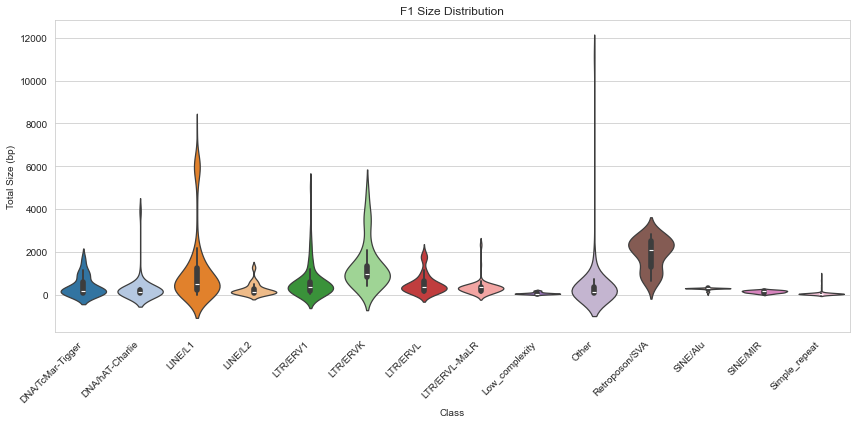

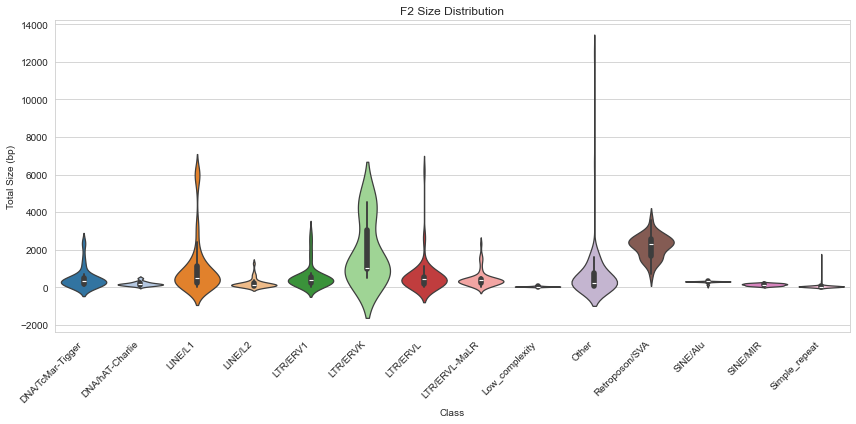

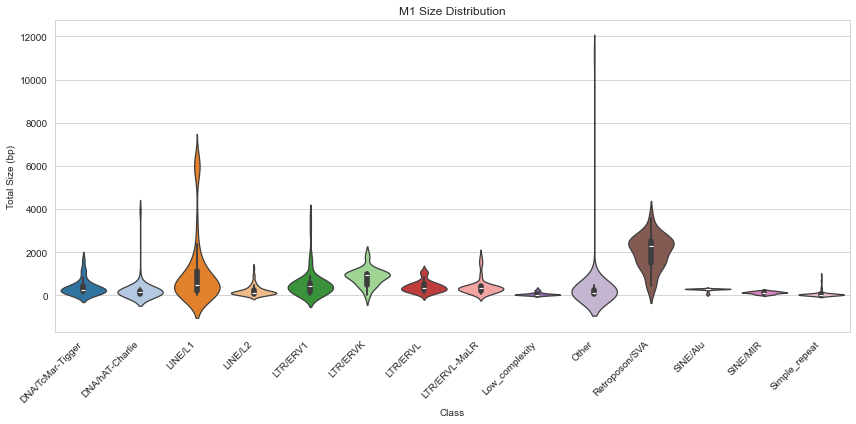

In [145]:
plot_size_distribution(F1_strong, title="F1 Size Distribution")
plot_size_distribution(F2_strong, title="F2 Size Distribution")
plot_size_distribution(M1_strong, title="M1 Size Distribution")

In [146]:
def plot_log_size_distribution(df, title="Log Size Distribution by Class"):
    """
    Dot plot of log-transformed alignment sizes colored by class.
    For rows sharing the same ID, sizes are summed together before log transform.
    Uses classes from GLOBAL_CLASS_COLORS.
    
    Args:
        df: dataframe with 'begin', 'end', 'class', and 'ID' columns
        title: plot title
    """
    df_copy = df.copy()
    df_copy['size'] = df_copy['end'] - df_copy['begin']
    
    # Group by ID and sum sizes
    df_aggregated = df_copy.groupby(['ID', 'class']).agg({
        'size': 'sum'
    }).reset_index()
    
    # Calculate log10(size)
    df_aggregated['log_size'] = np.log10(df_aggregated['size'])
    
    # Map to global classes
    global_classes = set(GLOBAL_CLASS_COLORS.keys()) - {'Other'}
    df_aggregated['class_grouped'] = df_aggregated['class'].apply(
        lambda x: x if x in global_classes else 'Other'
    )
    
    # Use all classes from global map (sorted alphabetically)
    all_global_classes = sorted(GLOBAL_CLASS_COLORS.keys())
    
    plt.figure(figsize=(12, 6))
    sns.violinplot(data=df_aggregated, x='class_grouped', y='log_size', 
                   hue='class_grouped', order=all_global_classes, palette=GLOBAL_CLASS_COLORS)
    plt.xlabel('Class')
    plt.ylabel('Log10(Total Size) [bp]')
    plt.title(title)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
    
    plt.savefig(f"/Users/aarontran/Desktop/wanglab/{title.replace(' ', '_')}.png", dpi=300, bbox_inches='tight', facecolor='white', transparent=False)
    plt.show()

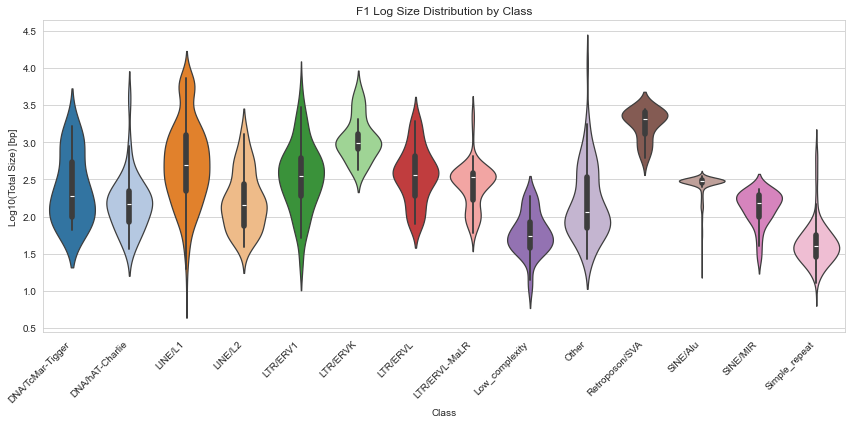

<Figure size 432x288 with 0 Axes>

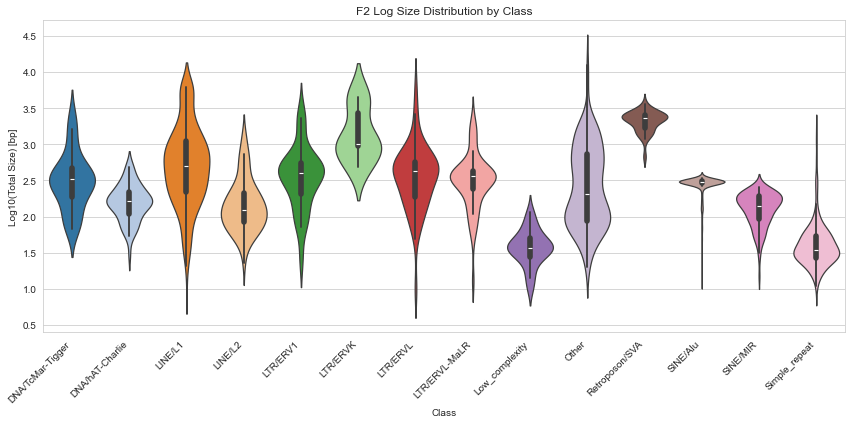

<Figure size 432x288 with 0 Axes>

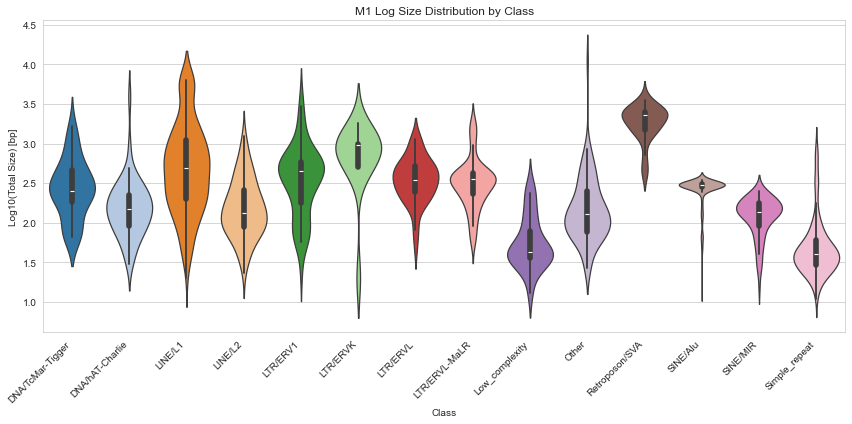

<Figure size 432x288 with 0 Axes>

In [147]:
plot_log_size_distribution(F1_strong, title="F1 Log Size Distribution by Class")
plot_log_size_distribution(F2_strong, title="F2 Log Size Distribution by Class")
plot_log_size_distribution(M1_strong, title="M1 Log Size Distribution by Class")

In [148]:
def plot_percdiv_distribution(df, title="Percent Divergence Distribution"):
    """
    Violin plot of percent divergence colored by class.
    For rows sharing the same ID, percent divergence is averaged.
    Uses classes from GLOBAL_CLASS_COLORS.
    
    Args:
        df: dataframe with 'perc div.', 'class', and 'ID' columns
        title: plot title
    """
    df_copy = df.copy()
    
    # Group by ID and average percent divergence
    df_aggregated = df_copy.groupby(['ID', 'class']).agg({
        'perc div.': 'mean'
    }).reset_index()
    
    # Map to global classes
    global_classes = set(GLOBAL_CLASS_COLORS.keys()) - {'Other'}
    df_aggregated['class_grouped'] = df_aggregated['class'].apply(
        lambda x: x if x in global_classes else 'Other'
    )
    
    # Use all classes from global map (sorted alphabetically)
    all_global_classes = sorted(GLOBAL_CLASS_COLORS.keys())
    
    plt.figure(figsize=(12, 6))
    sns.violinplot(data=df_aggregated, x='class_grouped', y='perc div.', 
                   order=all_global_classes, palette=GLOBAL_CLASS_COLORS)
    plt.xlabel('Class')
    plt.ylabel('Percent Divergence (%) [averaged per ID]')
    plt.title(title)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    
    plt.savefig(f"/Users/aarontran/Desktop/wanglab/{title.replace(' ', '_')}.png", dpi=300, bbox_inches='tight', facecolor='white', transparent=False)
    plt.show()

<ipython-input-148-6701b3bc0759>:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_aggregated, x='class_grouped', y='perc div.',


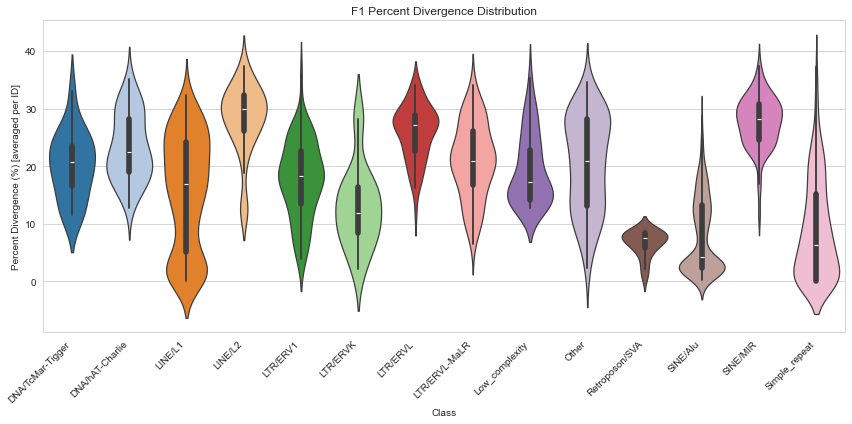

<ipython-input-148-6701b3bc0759>:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_aggregated, x='class_grouped', y='perc div.',


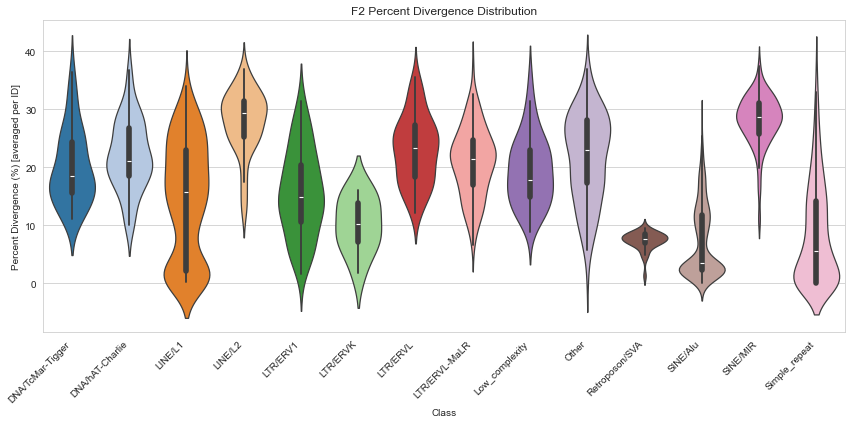

<ipython-input-148-6701b3bc0759>:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_aggregated, x='class_grouped', y='perc div.',


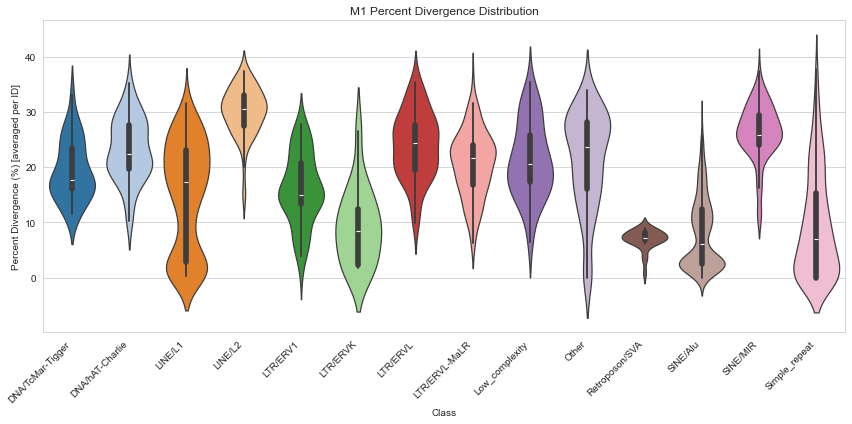

In [149]:
plot_percdiv_distribution(F1_strong, title="F1 Percent Divergence Distribution")
plot_percdiv_distribution(F2_strong, title="F2 Percent Divergence Distribution")
plot_percdiv_distribution(M1_strong, title="M1 Percent Divergence Distribution")

In [150]:
def plot_genomic_distribution(df, title="Genomic Distribution by Chromosome"):
    """
    Stacked bar chart showing class distribution by chromosome.
    Stacks are sorted by average count across chromosomes (highest at bottom).
    Uses classes from GLOBAL_CLASS_COLORS.
    
    Args:
        df: dataframe with 'query sequence', 'class', and 'ID' columns
        title: plot title
    """
    df_unique = df.drop_duplicates(subset='ID').copy()
    
    # Extract chromosome
    df_unique['chr'] = df_unique['query sequence'].str.extract(r'(chr\d+|chrX|chrY)')
    
    # Map to global classes
    global_classes = set(GLOBAL_CLASS_COLORS.keys()) - {'Other'}
    df_unique['class_grouped'] = df_unique['class'].apply(
        lambda x: x if x in global_classes else 'Other'
    )
    
    # Count elements per chromosome and class
    chr_class = df_unique.groupby(['chr', 'class_grouped']).size().unstack(fill_value=0)
    
    # Ensure all global classes are present (even if count is 0)
    all_global_classes = sorted(GLOBAL_CLASS_COLORS.keys())
    for cls in all_global_classes:
        if cls not in chr_class.columns:
            chr_class[cls] = 0
    
    # Sort chromosomes naturally
    def chr_sort_key(x):
        if x[3:].isdigit():
            return (0, int(x[3:]))
        else:
            return (1, x[3:])
    
    chr_order = sorted(chr_class.index, key=chr_sort_key)
    chr_class = chr_class.reindex(chr_order)
    
    # Calculate average count per chromosome for each class
    # Sort classes by average count (descending - highest average at bottom)
    class_avg_counts = chr_class.mean(axis=0).sort_values(ascending=False)
    sorted_classes = class_avg_counts.index.tolist()
    
    # Reorder columns
    chr_class = chr_class[sorted_classes]
    
    plt.figure(figsize=(14, 8))
    chr_class.plot(kind='bar', stacked=True, 
                   color=[GLOBAL_CLASS_COLORS[c] for c in sorted_classes], 
                   width=0.8, ax=plt.gca())
    
    plt.xlabel('Chromosome')
    plt.ylabel('Number of Unique Elements')
    plt.title(title)
    plt.legend(title='Class', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    
    plt.savefig(f"/Users/aarontran/Desktop/wanglab/{title.replace(' ', '_')}.png", dpi=300, bbox_inches='tight', facecolor='white', transparent=False)
    plt.show()

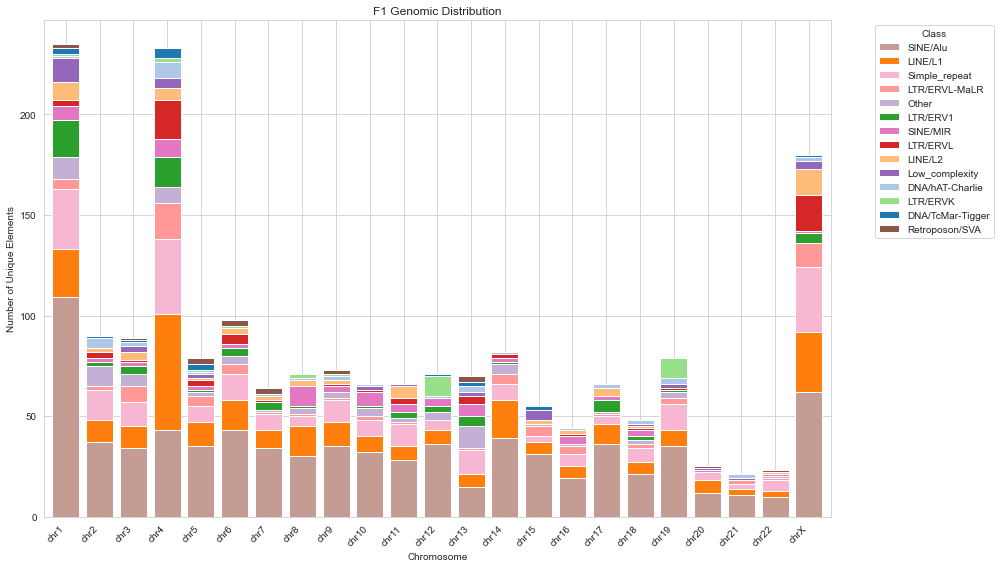

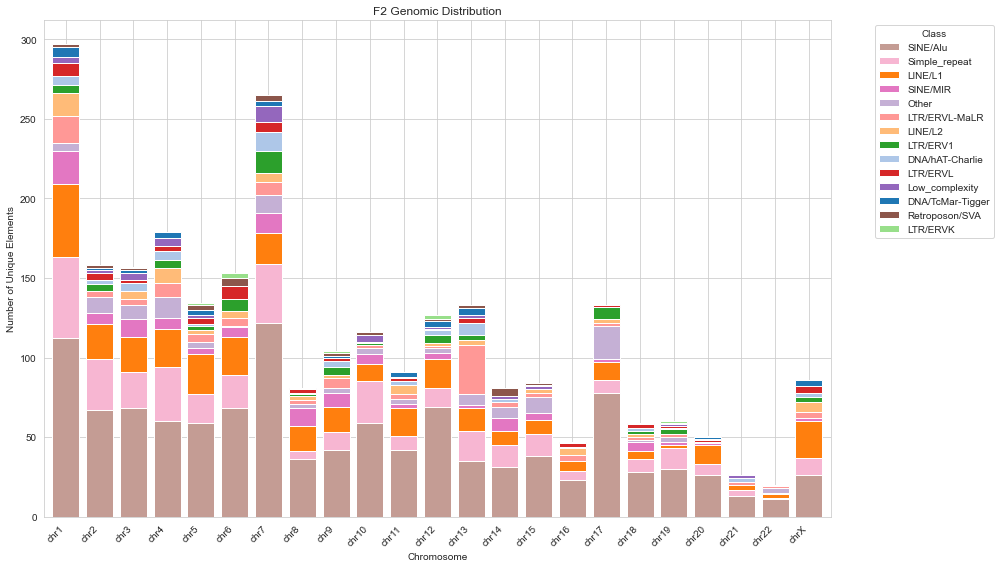

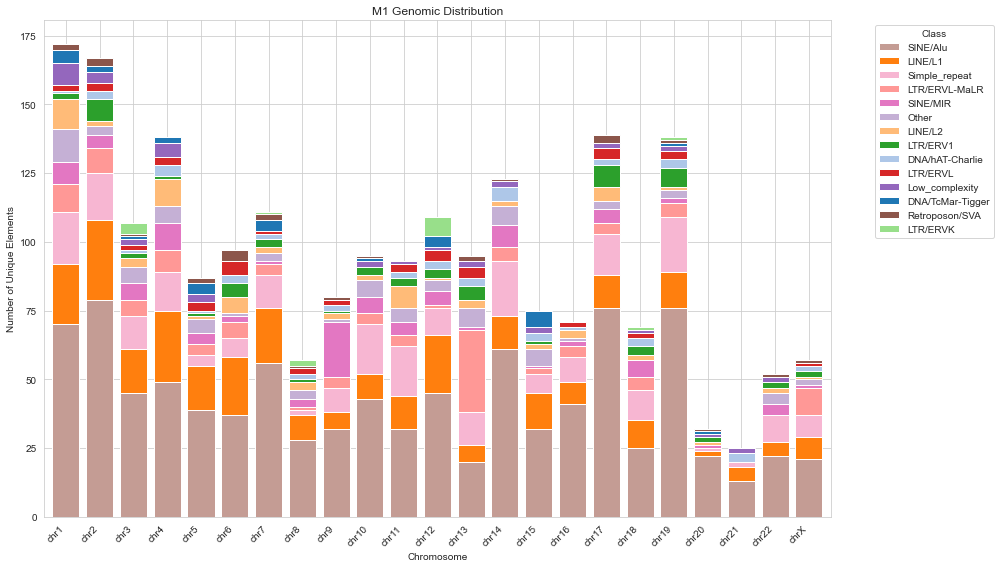

In [151]:
plot_genomic_distribution(F1_strong, title="F1 Genomic Distribution")
plot_genomic_distribution(F2_strong, title="F2 Genomic Distribution")
plot_genomic_distribution(M1_strong, title="M1 Genomic Distribution")

## This location distribution remains unexplained.

My best guess is this has something to do with the relative repeat content of each chromosome. Of course, it should also scale with the size of these chromosomes, but that's only slightly the case here. Generally, we should expect TEs to try to spread themselves out across the autosomes as much as possible because of competitive pressures. I was not able to explain this, and it remains open whether I'm missing some TEs through PanGenie or whether this reflects something meaningful.

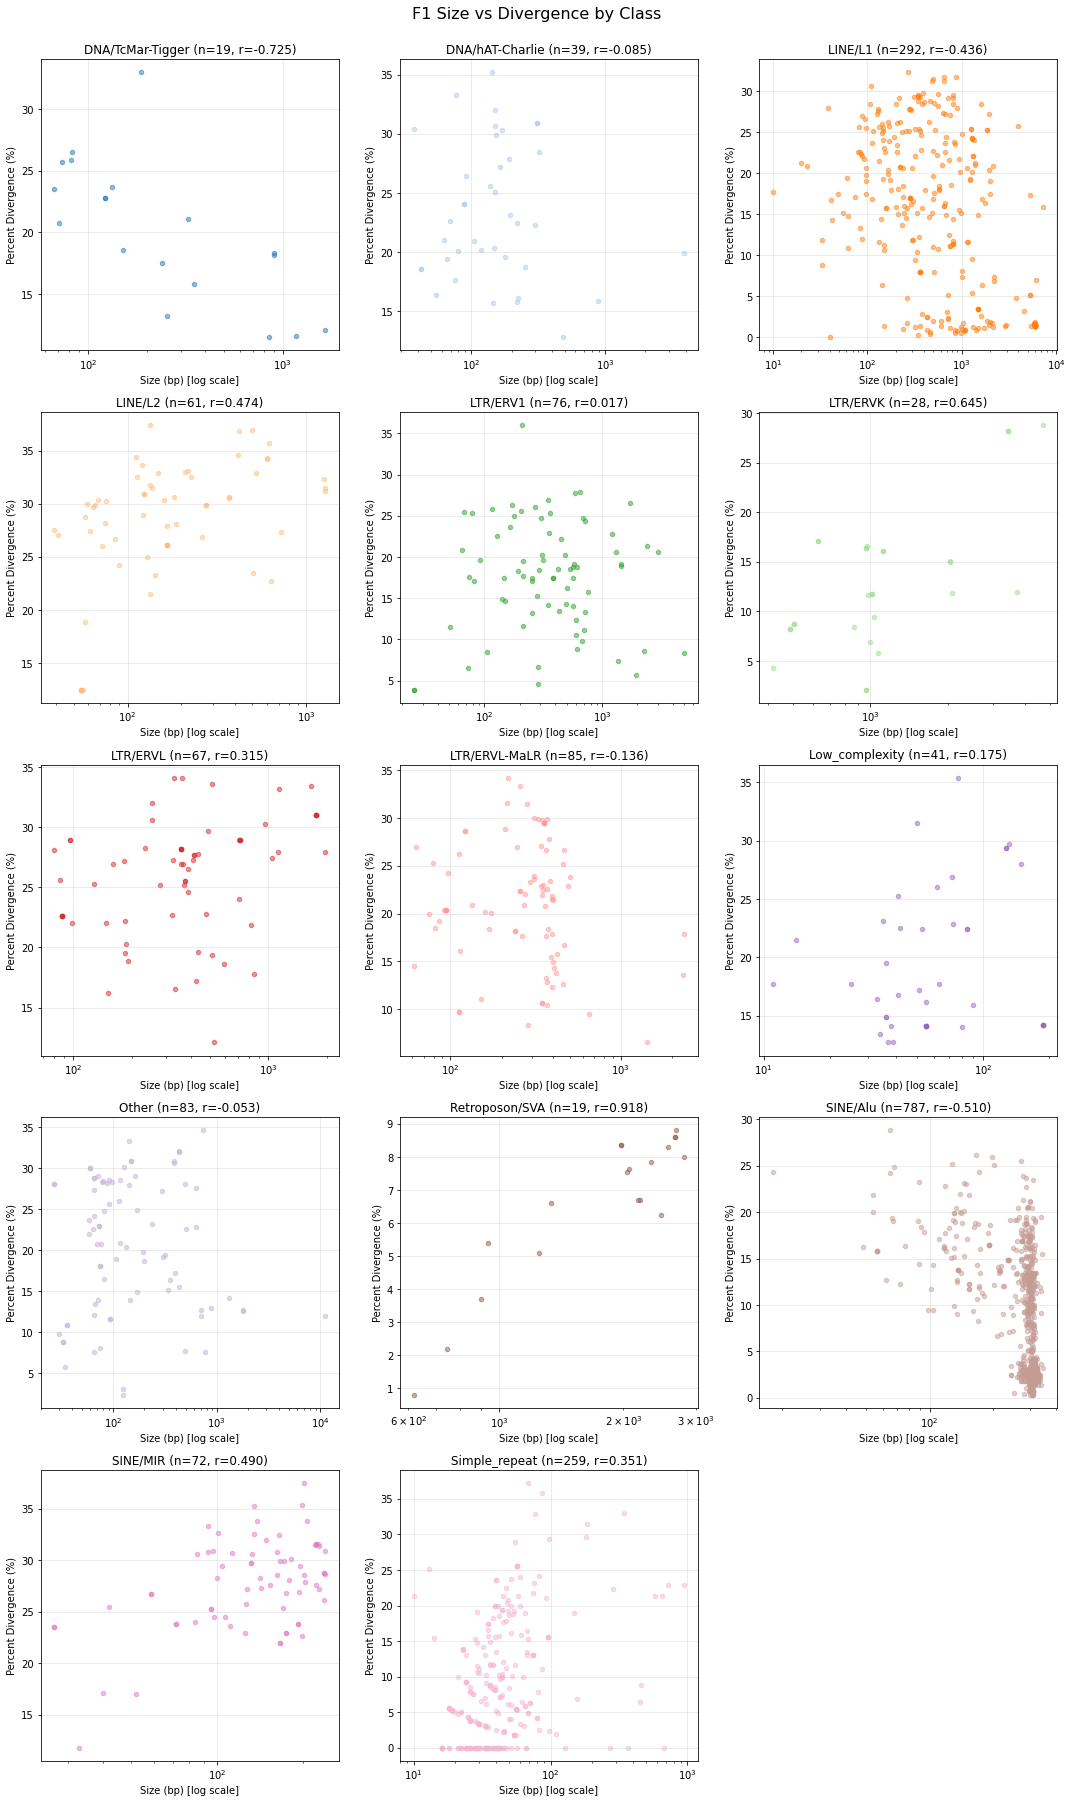

In [16]:
def plot_size_divergence_per_class(df, title="Size vs Divergence by Class", use_log=True):
    """
    Scatter plots of size vs divergence, one subplot per class.
    For rows sharing the same ID, sizes are summed and divergence is averaged.
    
    Args:
        df: dataframe with 'begin', 'end', 'perc div.', 'class', and 'ID' columns
        title: plot title
        use_log: if True, use log scale for size (default True)
    """
    df_copy = df.copy()
    df_copy['size'] = df_copy['end'] - df_copy['begin']
    
    # Group by ID and aggregate
    df_aggregated = df_copy.groupby(['ID', 'class']).agg({
        'size': 'sum',
        'perc div.': 'mean'
    }).reset_index()
    
    # Map to global classes
    global_classes = set(GLOBAL_CLASS_COLORS.keys()) - {'Other'}
    df_aggregated['class_grouped'] = df_aggregated['class'].apply(
        lambda x: x if x in global_classes else 'Other'
    )
    
    # Get all classes that have data
    classes_with_data = sorted(df_aggregated['class_grouped'].unique())
    n_classes = len(classes_with_data)
    
    # Calculate grid dimensions
    n_cols = 3
    n_rows = (n_classes + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5*n_rows))
    axes = axes.flatten() if n_classes > 1 else [axes]
    
    for idx, cls in enumerate(classes_with_data):
        ax = axes[idx]
        data = df_aggregated[df_aggregated['class_grouped'] == cls]
        
        # Calculate correlation
        if use_log and len(data) > 0:
            data_plot = data.copy()
            data_plot['log_size'] = np.log10(data_plot['size'])
            correlation = data_plot['perc div.'].corr(data_plot['log_size'])
        else:
            correlation = data['perc div.'].corr(data['size'])
        
        # Plot
        ax.scatter(data['size'], data['perc div.'], 
                  alpha=0.5, s=20, color=GLOBAL_CLASS_COLORS[cls])
        
        if use_log:
            ax.set_xscale('log')
            ax.set_xlabel('Size (bp) [log scale]')
        else:
            ax.set_xlabel('Size (bp)')
        
        ax.set_ylabel('Percent Divergence (%)')
        ax.set_title(f'{cls} (n={len(data)}, r={correlation:.3f})')
        ax.grid(True, alpha=0.3)
    
    # Hide extra subplots
    for idx in range(n_classes, len(axes)):
        axes[idx].axis('off')
    
    plt.suptitle(title, fontsize=16, y=1.00)
    plt.tight_layout()
    plt.show()


# Usage:
plot_size_divergence_per_class(F1_strong, title="F1 Size vs Divergence by Class")

Of some interest is the correlation between size and divergence. This makes sense--the larger you are, the more space you'll have for mutations to accumulate, and the higher the likelihood that selective pressures are trying to clean you up, so to speak.